# Stage 2: Feature Engineering & Preprocessing Pipeline

Derive `vehicle_age`, `km_10k`, and numeric `owner_num`, perform brand-level median imputation for unparsed `'Unknown'` specs, and validate the `ColumnTransformer` preprocessing matrix.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.pipeline import list_data_files, clean_specifications, engineer_features, build_preprocessor

v3_raw_clean, _, _ = clean_specifications(ROOT / 'data' / 'Car details v3.csv')
print('Missing counts BEFORE imputation:', {k: int(v) for k, v in v3_raw_clean.isna().sum().items() if v > 0})
v3_feat = engineer_features(v3_raw_clean)
print('Missing counts AFTER imputation:', {k: int(v) for k, v in v3_feat.isna().sum().items() if v > 0})
print('\nEngineered columns sample:')
print(v3_feat[['brand', 'year', 'vehicle_age', 'km_driven', 'km_10k', 'owner_num', 'price_lakh']].head(6).to_string(index=False))

Missing counts BEFORE imputation: {'torque_nm': 206}
Missing counts AFTER imputation: {}

Engineered columns sample:
  brand  year  vehicle_age  km_driven  km_10k  owner_num  price_lakh
 Maruti  2014            6     145500   14.55          1        4.50
  Skoda  2014            6     120000   12.00          2        3.70
  Honda  2006           14     140000   14.00          3        1.58
Hyundai  2010           10     127000   12.70          1        2.25
 Maruti  2007           13     120000   12.00          1        1.30
Hyundai  2017            3      45000    4.50          1        4.40


In [2]:
rows = []
for path in list_data_files():
    df_c, _, _ = clean_specifications(path)
    df_f = engineer_features(df_c)
    pre, num_feats, cat_feats = build_preprocessor(df_f)
    enc = pre.fit_transform(df_f[cat_feats + num_feats])
    rows.append({
        'Dataset': path.name,
        'Rows': len(df_f),
        'Snapshot Year': int(df_f['year'].max()),
        'Max Age (yrs)': int(df_f['vehicle_age'].max()),
        'Numeric Feats': len(num_feats),
        'Encoded Matrix Shape': str(enc.shape),
    })
print(pd.DataFrame(rows).to_string(index=False))

                       Dataset  Rows  Snapshot Year  Max Age (yrs)  Numeric Feats Encoded Matrix Shape
            Car details v3.csv  6908           2020             37              8           (6908, 46)
            car details v4.csv  2054           2022             34              7           (2054, 51)
CAR DETAILS FROM CAR DEKHO.csv  3577           2020             28              3           (3577, 39)
                  car data.csv   299           2018             15              3            (299, 48)


=== Correlation with Price (INR Lakhs) ===
price_lakh      1.000
vehicle_age    -0.433
km_10k         -0.166
power_bhp       0.689
engine_cc       0.444
torque_nm       0.474
mileage_kmpl   -0.107
owner_num      -0.255


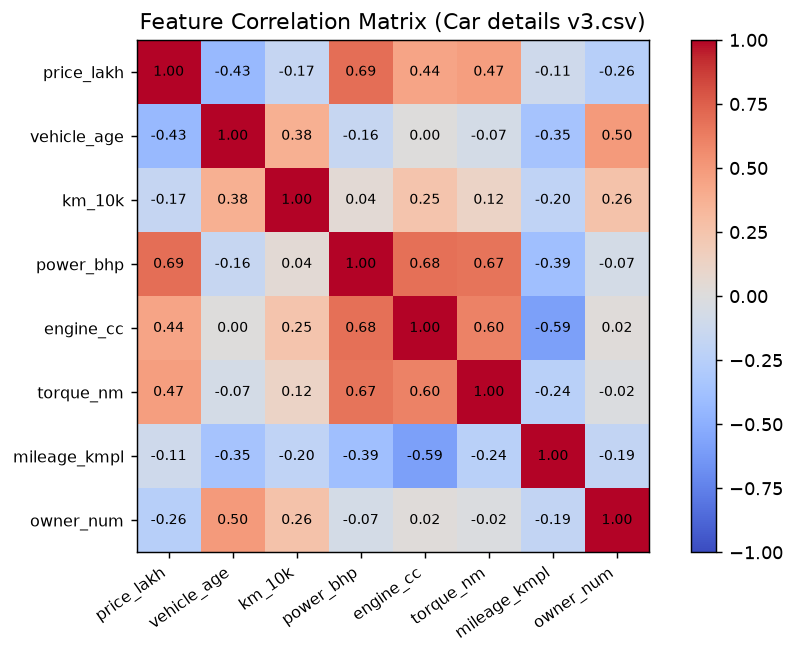

In [3]:
corr_cols = ['price_lakh', 'vehicle_age', 'km_10k', 'power_bhp', 'engine_cc', 'torque_nm', 'mileage_kmpl', 'owner_num']
corr = v3_feat[corr_cols].corr()
print('=== Correlation with Price (INR Lakhs) ===')
print(corr['price_lakh'].round(3).to_string())

fig, ax = plt.subplots(figsize=(7.2, 5.2))
im = ax.imshow(corr.values, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=35, ha='right', fontsize=9)
ax.set_yticks(range(len(corr_cols)))
ax.set_yticklabels(corr_cols, fontsize=9)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', fontsize=8, color='black')
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set_title('Feature Correlation Matrix (Car details v3.csv)')
plt.tight_layout()
plt.show()